In [ ]:
import pandas as pd
import numpy as np
import re
import html
import time
import joblib
import warnings
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, make_scorer)
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
RANDOM_STATE = 42
BEST_PREPROCESSING = "E2"
N_SPLITS = 3
N_ITERATIONS = 4
print("Random state:", RANDOM_STATE)
print("Selected preprocessing:", BEST_PREPROCESSING)
print("Cross-validation folds:", N_SPLITS)
print("Random search iterations per model:", N_ITERATIONS)

Random state: 42
Selected preprocessing: E2
Cross-validation folds: 3
Random search iterations per model: 4


In [ ]:
PROJECT_ROOT = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "data" / "processed" / "train.csv"
    if candidate.exists():
        PROJECT_ROOT = folder
        DATA_PATH = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate data/processed/train.csv.")
train_df = pd.read_csv(DATA_PATH)
print("Project root:", PROJECT_ROOT)
print("Dataset shape:", train_df.shape)
print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

Project root: c:\Users\VRINDA ARORA\OneDrive\Desktop\Sentient-Beings-Review-Sentiment
Dataset shape: (40000, 3)

Sentiment distribution:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64


In [ ]:
X = train_df["review"]
y = train_df["sentiment"]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("\nTraining distribution:")
print(y_train.value_counts())
print("\nValidation distribution:")
print(y_val.value_counts())

Training samples: 32000
Validation samples: 8000

Training distribution:
sentiment
negative    16000
positive    16000
Name: count, dtype: int64

Validation distribution:
sentiment
positive    4000
negative    4000
Name: count, dtype: int64


In [ ]:
def remove_html(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = html.unescape(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
def lowercase(text):
    return text.lower()
def remove_punctuation(text):
    return re.sub(r"[^\w\s]", " ", text)
def remove_stopwords(text):
    words = text.split()
    return " ".join(word for word in words if word not in ENGLISH_STOP_WORDS)
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer
try:
    nltk.data.find("corpora/wordnet")
except LookupError:
    nltk.download("wordnet")
try:
    nltk.data.find("corpora/omw-1.4")
except LookupError:
    nltk.download("omw-1.4")
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
def stem_text(text):
    return " ".join(stemmer.stem(word) for word in text.split())
def lemmatize_text(text):
    return " ".join(lemmatizer.lemmatize(word) for word in text.split())
def preprocess_E1(text): return remove_html(text)
def preprocess_E2(text): return lowercase(remove_html(text))
def preprocess_E3(text): return remove_punctuation(lowercase(remove_html(text)))
def preprocess_E4(text): return remove_stopwords(preprocess_E3(text))
def preprocess_E5(text): return stem_text(preprocess_E4(text))
def preprocess_E6(text): return lemmatize_text(preprocess_E4(text))
PREPROCESSING_OPTIONS = {"E1": preprocess_E1, "E2": preprocess_E2, "E3": preprocess_E3,
                         "E4": preprocess_E4, "E5": preprocess_E5, "E6": preprocess_E6}
if BEST_PREPROCESSING not in PREPROCESSING_OPTIONS:
    raise ValueError("Invalid preprocessing selection!")
selected_preprocessor = PREPROCESSING_OPTIONS[BEST_PREPROCESSING]
print("Preprocessing function selected:", BEST_PREPROCESSING)

Preprocessing function selected: E2


[nltk_data] Downloading package wordnet to C:\Users\VRINDA
[nltk_data]     ARORA\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\VRINDA
[nltk_data]     ARORA\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:
comparison_path = PROJECT_ROOT / "results" / "model_comparison_results.csv"
if not comparison_path.exists():
    raise FileNotFoundError("Notebook 04 results not found. ")
comparison_df = pd.read_csv(comparison_path)
vectorizer_summary = (comparison_df.groupby("Vectorizer")["F1-Score"].mean().sort_values(ascending=False))
print("AVERAGE F1-SCORE BY VECTORIZER")
display(vectorizer_summary.to_frame())
BEST_VECTORIZER = vectorizer_summary.index[0]
print("\nSelected vectorizer:", BEST_VECTORIZER)

AVERAGE F1-SCORE BY VECTORIZER


,F1-Score
Vectorizer,
TF-IDF,0.884918
Bag-of-Words,0.866661



Selected vectorizer: TF-IDF


In [ ]:
def create_vectorizer():
    if BEST_VECTORIZER == "Bag-of-Words":
        return CountVectorizer(preprocessor=selected_preprocessor, lowercase=False, token_pattern=r"(?u)\b\w\w+\b")
    elif BEST_VECTORIZER == "TF-IDF":
        return TfidfVectorizer(preprocessor=selected_preprocessor, lowercase=False, token_pattern=r"(?u)\b\w\w+\b")
    raise ValueError("Unknown vectorizer selected!")
print("Vectorizer configured:", BEST_VECTORIZER)

Vectorizer configured: TF-IDF


In [ ]:

models = {
    "Logistic Regression": LogisticRegression(solver="liblinear", max_iter=1000, random_state=RANDOM_STATE),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(max_iter=5000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE)
}
param_distributions = {
    "Logistic Regression": {
        "classifier__C": [0.1, 0.5, 1, 3, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    "Multinomial Naive Bayes": {
        "classifier__alpha": [0.1, 0.5, 1.0, 2.0],
        "classifier__fit_prior": [True, False]
    },
    "Linear SVM": {
        "classifier__C": [0.1, 0.5, 1, 3, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "classifier__max_depth": [10, 20, 30, 50, None],
        "classifier__min_samples_split": [2, 5, 10, 20],
        "classifier__min_samples_leaf": [1, 2, 5, 10],
        "classifier__class_weight": [None, "balanced"]
    }
}
print("Models and hyperparameter search spaces configured!")

Models and hyperparameter search spaces configured!


In [ ]:
cv_strategy = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
f1_scorer = make_scorer(f1_score, pos_label="positive")
print("Cross-validation strategy configured!")
print("Number of folds:", N_SPLITS)
print("Scoring metric: F1-score")

Cross-validation strategy configured!
Number of folds: 3
Scoring metric: F1-score


In [ ]:
tuning_results = []
best_estimators = {}
for model_name, classifier in models.items():
    print("\n" + "=" * 65)
    print("TUNING:", model_name)
    print("=" * 65)
    pipeline = Pipeline([("vectorizer", create_vectorizer()), ("classifier", classifier)])
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[model_name],
        n_iter=N_ITERATIONS,
        scoring=f1_scorer,
        cv=cv_strategy,
        refit=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=1)
    start_time = time.time()
    search.fit(X_train, y_train)
    tuning_time = time.time() - start_time
    best_estimators[model_name] = search.best_estimator_
    tuning_results.append({
        "Model": model_name,
        "Best CV F1-Score": search.best_score_,
        "Best Parameters": search.best_params_,
        "Tuning Time (seconds)": tuning_time})
    print("Best CV F1-score:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)
    print("Tuning time:", round(tuning_time, 2), "seconds")
print("\nAll four models tuned successfully!")


TUNING: Logistic Regression
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best CV F1-score: 0.896
Best parameters: {'classifier__class_weight': None, 'classifier__C': 10}
Tuning time: 127.84 seconds

TUNING: Multinomial Naive Bayes
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best CV F1-score: 0.855
Best parameters: {'classifier__fit_prior': False, 'classifier__alpha': 0.1}
Tuning time: 113.45 seconds

TUNING: Linear SVM
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best CV F1-score: 0.8939
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__C': 1}
Tuning time: 136.52 seconds

TUNING: Decision Tree
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best CV F1-score: 0.7434
Best parameters: {'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 10, 'classifier__max_depth': 20, 'classifier__class_weight': 'balanced'}
Tuning time: 371.31 seconds

All four models tuned successfully!


In [ ]:
cv_results_df = pd.DataFrame(tuning_results)
cv_results_df = cv_results_df.sort_values(by="Best CV F1-Score", ascending=False).reset_index(drop=True)
print("CROSS-VALIDATION AND TUNING RESULTS\n")
display(cv_results_df.round(4))
print("\nBest model based on cross-validation:")
print(cv_results_df.iloc[0]["Model"])

CROSS-VALIDATION AND TUNING RESULTS



,Model,Best CV F1-Score,Best Parameters,Tuning Time (seconds)
0,Logistic Regression,0.8960,"{'classifier__class_weight': None, 'classifier...",127.8408
1,Linear SVM,0.8939,"{'classifier__class_weight': 'balanced', 'clas...",136.5225
2,Multinomial Naive Bayes,0.8550,"{'classifier__fit_prior': False, 'classifier__...",113.4479
3,Decision Tree,0.7434,"{'classifier__min_samples_split': 2, 'classifi...",371.3062



Best model based on cross-validation:
Logistic Regression


In [ ]:
validation_results = []
validation_estimators = {}
for model_name, estimator in best_estimators.items():
    print("\nEvaluating:", model_name)
    y_pred = estimator.predict(X_val)
    classifier = estimator.named_steps["classifier"]
    if hasattr(classifier, "predict_proba"):
        positive_index = list(classifier.classes_).index("positive")
        y_scores = estimator.predict_proba(X_val)[:, positive_index]
    else:
        y_scores = estimator.decision_function(X_val)
    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, pos_label="positive"),
        "Recall": recall_score(y_val, y_pred, pos_label="positive"),
        "F1-Score": f1_score(y_val, y_pred, pos_label="positive"),
        "ROC-AUC": roc_auc_score((y_val == "positive").astype(int), y_scores)
    })
    validation_estimators[model_name] = estimator
validation_results_df = pd.DataFrame(validation_results)
validation_results_df = validation_results_df.sort_values(by=["F1-Score", "ROC-AUC"], ascending=False).reset_index(drop=True)
print("\nTUNED MODEL VALIDATION RESULTS\n")
display(validation_results_df.round(4))


Evaluating: Logistic Regression

Evaluating: Multinomial Naive Bayes

Evaluating: Linear SVM

Evaluating: Decision Tree

TUNED MODEL VALIDATION RESULTS



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9008,0.8941,0.9092,0.9016,0.9641
1,Linear SVM,0.8994,0.8907,0.9105,0.9005,0.9640
2,Multinomial Naive Bayes,0.8664,0.8719,0.8590,0.8654,0.9364
3,Decision Tree,0.7249,0.6963,0.7978,0.7436,0.7761


In [ ]:
best_validation_result = validation_results_df.iloc[0]
best_model_name = best_validation_result["Model"]
best_model = validation_estimators[best_model_name]
print("=" * 60)
print("BEST TUNED MODEL")
print("=" * 60)
print("Model:", best_model_name)
print("Vectorizer:", BEST_VECTORIZER)
print("Preprocessing:", BEST_PREPROCESSING)
print("\nValidation performance:")
for metric in ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]:
    print(f"{metric}: {best_validation_result[metric]:.4f}")
print("\nBest hyperparameters:")
print(cv_results_df.loc[cv_results_df["Model"] == best_model_name, "Best Parameters"].iloc[0])

BEST TUNED MODEL
Model: Logistic Regression
Vectorizer: TF-IDF
Preprocessing: E2

Validation performance:
Accuracy: 0.9008
Precision: 0.8941
Recall: 0.9093
F1-Score: 0.9016
ROC-AUC: 0.9641

Best hyperparameters:
{'classifier__class_weight': None, 'classifier__C': 10}


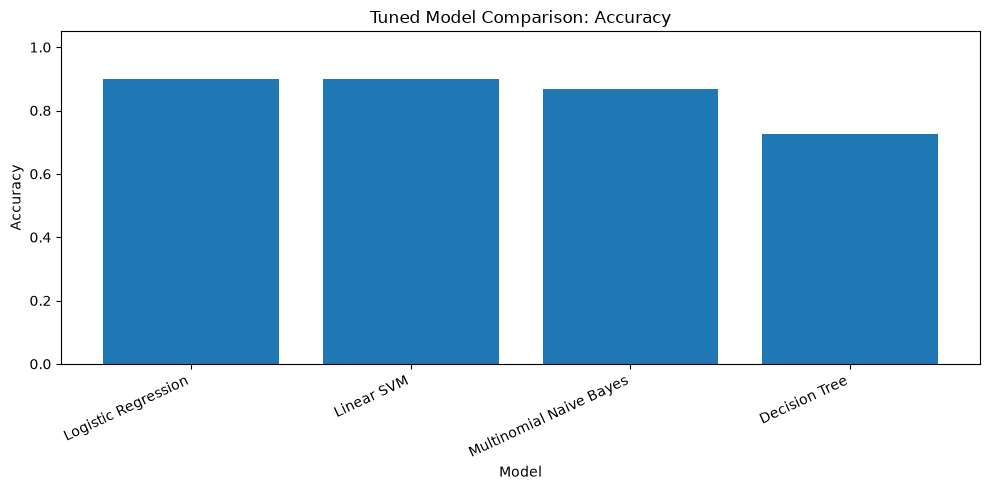

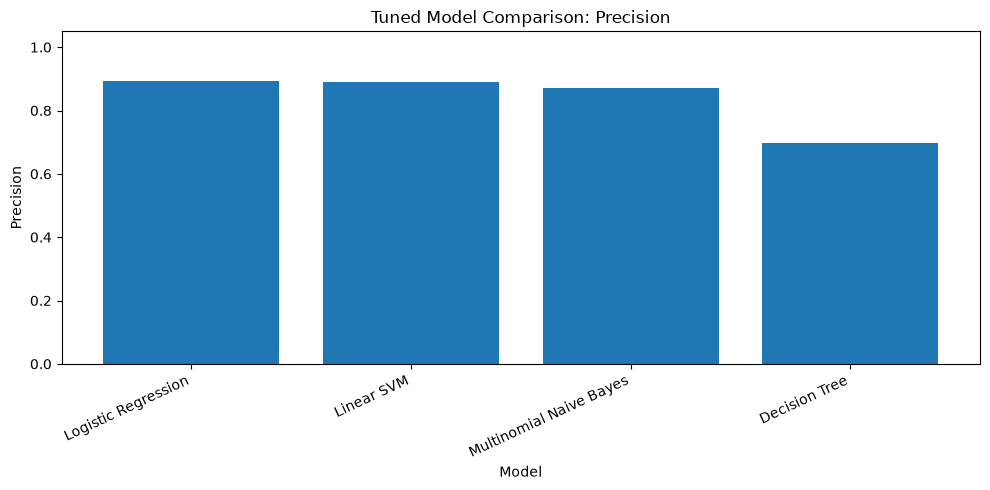

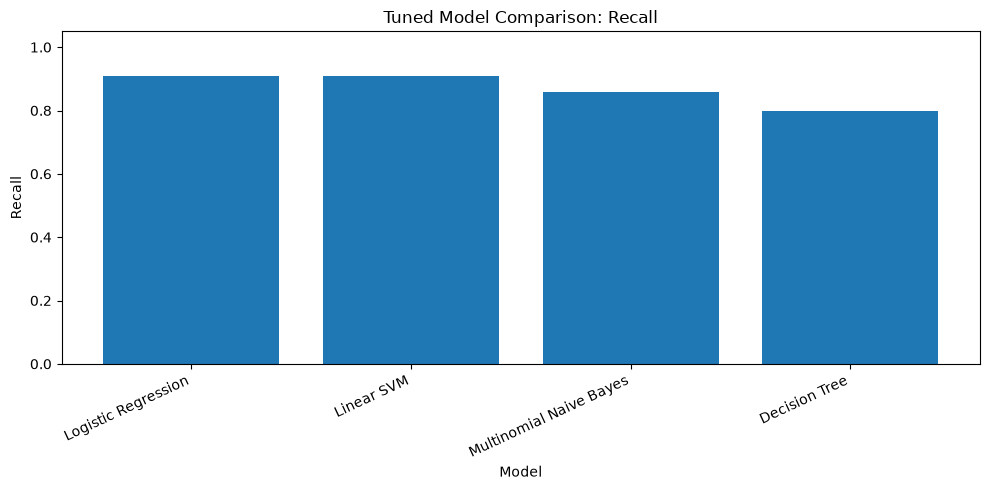

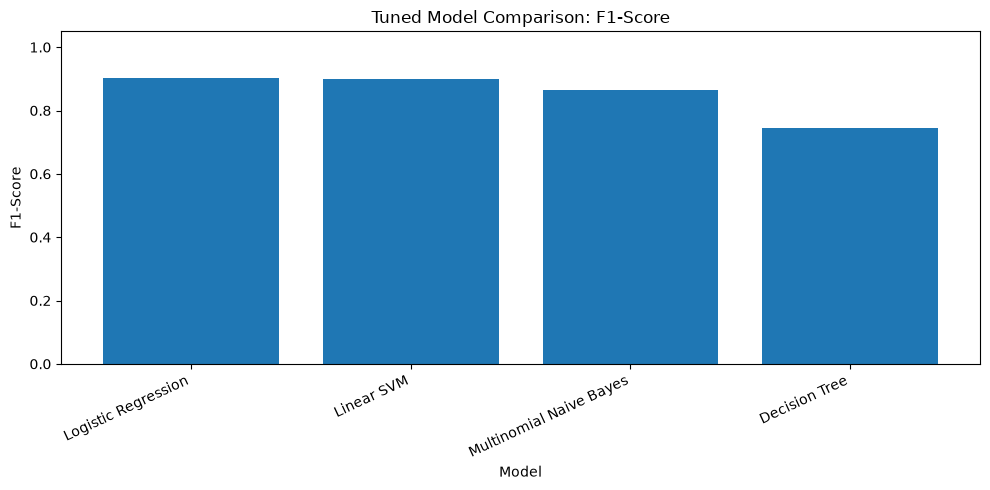

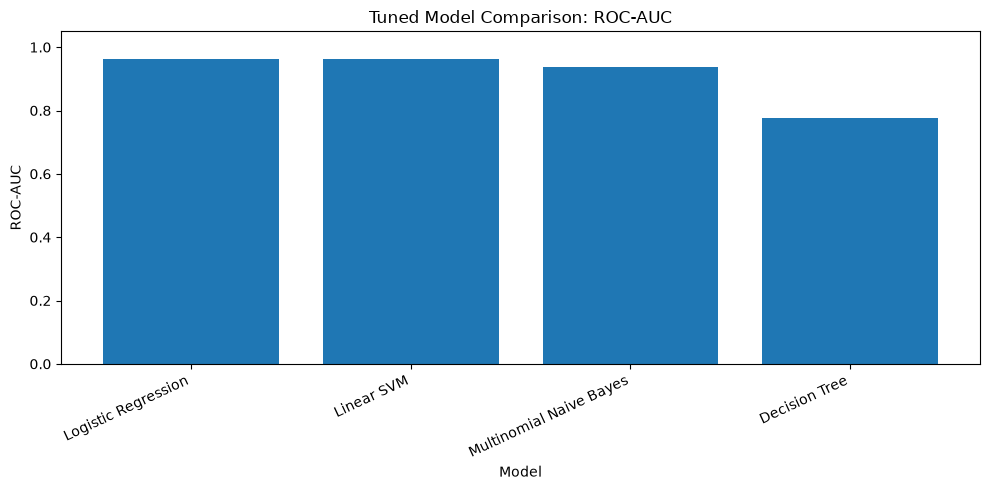

In [ ]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))
    plt.bar(validation_results_df["Model"], validation_results_df[metric])
    plt.title(f"Tuned Model Comparison: {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      4000
    Positive       0.89      0.91      0.90      4000

    accuracy                           0.90      8000
   macro avg       0.90      0.90      0.90      8000
weighted avg       0.90      0.90      0.90      8000



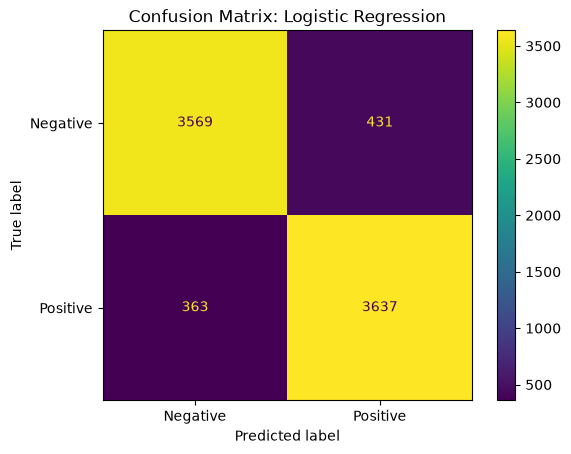

In [ ]:
best_predictions = best_model.predict(X_val)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_val, best_predictions, labels=["negative", "positive"], target_names=["Negative", "Positive"]))
cm = confusion_matrix(y_val, best_predictions, labels=["negative", "positive"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot()
plt.title(f"Confusion Matrix: {best_model_name}")
plt.show()

In [ ]:
results_dir = PROJECT_ROOT / "results"
models_dir = results_dir / "models"
results_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)
cv_results_df.to_csv(results_dir / "cross_validation_results.csv", index=False)
validation_results_df.to_csv(results_dir / "tuned_model_validation_results.csv", index=False)
joblib.dump(best_model, models_dir / "best_tuned_model.pkl")
predictions_df = pd.DataFrame({
    "review": X_val.reset_index(drop=True),
    "actual_sentiment": y_val.reset_index(drop=True),
    "predicted_sentiment": best_predictions})
predictions_df.to_csv(results_dir / "tuned_model_validation_predictions.csv", index=False)
print("Results and best tuned model saved successfully!")
print("Saved in:", results_dir)

Results and best tuned model saved successfully!
Saved in: c:\Users\VRINDA ARORA\OneDrive\Desktop\Sentient-Beings-Review-Sentiment\results


In [17]:
# Cell 17: Final experiment summary
print("=" * 65)
print("NOTEBOOK 05: CROSS-VALIDATION AND HYPERPARAMETER TUNING")
print("=" * 65)
print("\nPreprocessing:", BEST_PREPROCESSING)
print("Vectorizer:", BEST_VECTORIZER)
print("\nBest tuned model:", best_model_name)
print("\nValidation performance:")
print(f"Accuracy:  {best_validation_result['Accuracy']:.4f}")
print(f"Precision: {best_validation_result['Precision']:.4f}")
print(f"Recall:    {best_validation_result['Recall']:.4f}")
print(f"F1-score:  {best_validation_result['F1-Score']:.4f}")
print(f"ROC-AUC:   {best_validation_result['ROC-AUC']:.4f}")
print("\nModels tuned:", len(models))
print("Cross-validation folds:", N_SPLITS)
print("\nNotebook 05 completed successfully!")

NOTEBOOK 05: CROSS-VALIDATION AND HYPERPARAMETER TUNING

Preprocessing: E2
Vectorizer: TF-IDF

Best tuned model: Logistic Regression

Validation performance:
Accuracy:  0.9008
Precision: 0.8941
Recall:    0.9093
F1-score:  0.9016
ROC-AUC:   0.9641

Models tuned: 4
Cross-validation folds: 3

Notebook 05 completed successfully!
